#### ▶ 비선형 이진 분류(동심원 데이터)

In [85]:
import torch
import matplotlib.pyplot as plt 


#### Step 1. 데이터 생성 

In [86]:
N = 100 

radius1 = 0.3 + 0.05*torch.randn(int(N/2), 1) # 평균 : 0.3, 표준편차 : 0.05 # 0.3 주변의 값 (50)

radius2 = 1 + 0.01*torch.randn(int(N/2), 1) # 평균 : 1, 표준편차 : 0.01  # 1 주변의 값 (50)

# 각도 만들기 
theta1 = 2 * torch.pi * torch.rand(int(N/2), 1) - torch.pi ## -pi~ pi 까지의 주편각으로 계산하는것이 편해서 pi를 빼는것임. 
theta2 = 2 * torch.pi * torch.rand(int(N/2), 1) - torch.pi

# (x,y) 좌표로 바꾸기, 극좌표를 직교좌표계로 변환
# x = rcos, y = rsin
class1_data = torch.hstack([radius1*torch.cos(theta1), radius1*torch.sin(theta1)])
class2_data = torch.hstack([radius2*torch.cos(theta2), radius2*torch.sin(theta2)])

class1_label = torch.ones(int(N/2),1)
class2_label = torch.zeros(int(N/2),1)

X = torch.vstack([class1_data, class2_data])
y = torch.vstack([class1_label, class2_label])

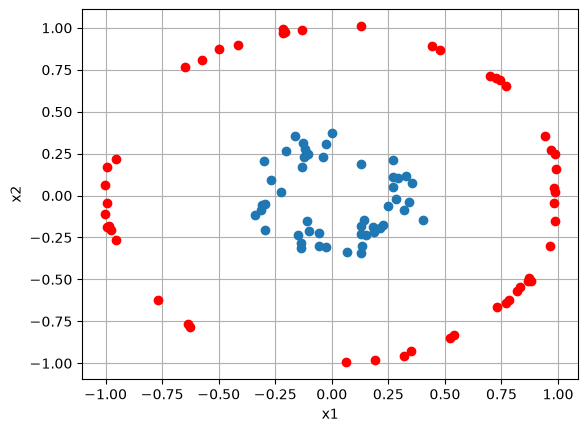

In [87]:
plt.plot(class1_data[:,0], class1_data[:,1],'o')
plt.plot(class2_data[:,0], class2_data[:,1],'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()


#### Step 2. 모델 만들기 

In [ ]:
from torch import nn 

class MLP(nn.Module) : 
    def __init__(self) : 
        super().__init__()

        # self.linear = nn.Sequential(nn.Linear(2,1000),
        #                             nn.Sigmoid(),
        #                             nn.Linear(1000,1),
        #                             nn.Sigmoid()
        # )

        # 선형분류에서만 가능
        # self.linear = nn.Sequential(nn.Linear(2,1000),
        #                             nn.Sigmoid())
        
        self.linear = nn.Sequential(nn.Linear(2,100),
                                    nn.ReLU(),
                                    *[nn.Sequential(nn.Linear(100,100), nn.ReLU())]
                                    nn.Linear(100,1),
                                    nn.Sigmoid())     

    def forward(self, x) : 
        x = self.linear(x)
        return x 

In [89]:
model = MLP()

#### Step 3. 모델 학습 시키기 

In [94]:
from torch import optim 

# LR = 1e-1
# EPOCH = 100

LR = 1e-4
EPOCH = 300 
# 은닉층이 많으면 학습률을 줄이고 epoch를 늘려보기


optimizer = optim.Adam(model.parameters(), lr = LR)
# optimizer = optim.Adam(model.parameters(), lr = LR) # 선형이 아니라서 잘 안됨. 
criterion = nn.BCELoss()

loss_history = []

model.train()  # train 모드로 변환
for ep in range(EPOCH) : 
    # inference
    y_hat = model(X)

    # loss
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]

    # print
    print(f'EPOCH : {ep+1}, train Loss : {loss.item():.4f}')
    print('-'*20)

EPOCH : 1, train Loss : 0.0000
--------------------
EPOCH : 2, train Loss : 0.0000
--------------------
EPOCH : 3, train Loss : 0.0000
--------------------
EPOCH : 4, train Loss : 0.0000
--------------------
EPOCH : 5, train Loss : 0.0000
--------------------
EPOCH : 6, train Loss : 0.0000
--------------------
EPOCH : 7, train Loss : 0.0000
--------------------
EPOCH : 8, train Loss : 0.0000
--------------------
EPOCH : 9, train Loss : 0.0000
--------------------
EPOCH : 10, train Loss : 0.0000
--------------------
EPOCH : 11, train Loss : 0.0000
--------------------
EPOCH : 12, train Loss : 0.0000
--------------------
EPOCH : 13, train Loss : 0.0000
--------------------
EPOCH : 14, train Loss : 0.0000
--------------------
EPOCH : 15, train Loss : 0.0000
--------------------
EPOCH : 16, train Loss : 0.0000
--------------------
EPOCH : 17, train Loss : 0.0000
--------------------
EPOCH : 18, train Loss : 0.0000
--------------------
EPOCH : 19, train Loss : 0.0000
--------------------
EP

Text(0, 0.5, 'Loss')

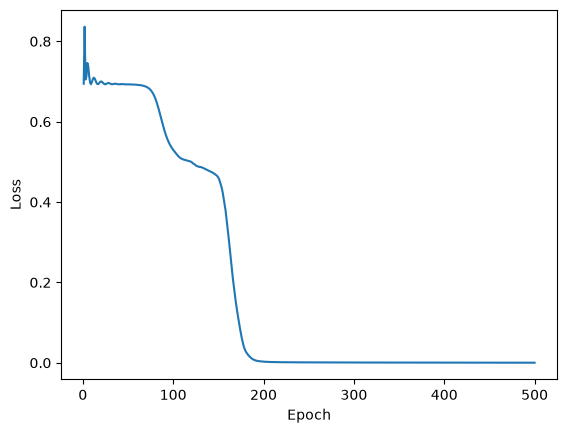

In [91]:
plt.plot(range(1, EPOCH+1), loss_history), # adam의 특징 : 처음에는 진동하다가 수렴함
plt.xlabel('Epoch')
plt.ylabel('Loss')

#### Step 4. 모델 테스트 

Text(0.5, 0.5, 'y1')

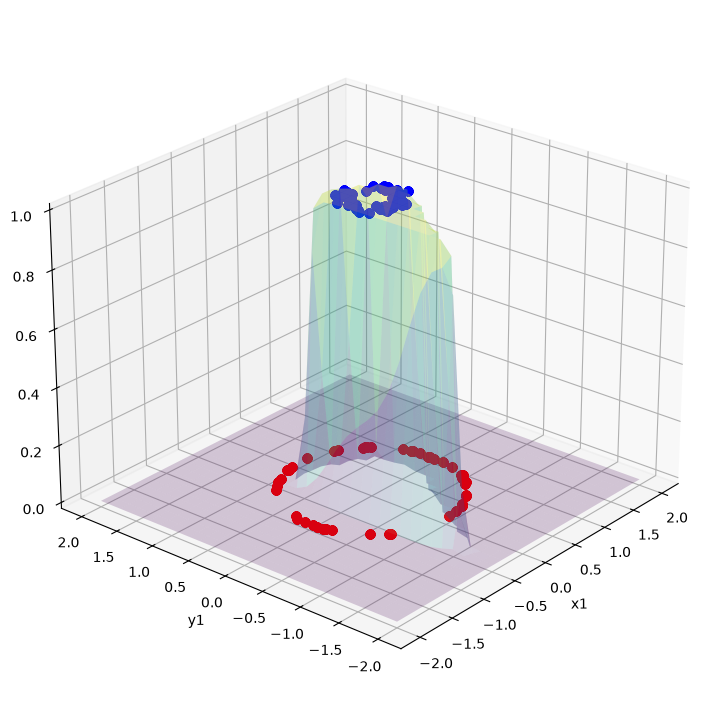

In [92]:
x1_test = torch.linspace(-2,2,30)
x2_test = torch.linspace(-2,2,30)

X1_test, X2_test = torch.meshgrid(x1_test, x2_test)
X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2)

model.eval() # test mode로 변환 
with torch.no_grad() : 
    y_hat = model(X_test)

Y_hat = y_hat.squeeze()

plt.figure(figsize=(10,9))
ax = plt.axes(projection = '3d')
ax.view_init(elev = 25, azim = -140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap = 'viridis', alpha = 0.2)
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('y1')